In [5]:

%pip install --no-cache-dir --upgrade "datasets>=4.8.5"

%pip install --no-cache-dir --force-reinstall "huggingface-hub==0.36.2"



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 44.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 218.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.6/801.6 kB 612.9 MB/s  0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0
  Attempting uninstall: tqdm
    Found existing installation: tqdm 4.67.3
    Uninstalling tqdm-4.67.3:
      Successfully uninstalled tqdm-4.67.3
  Attempting uninstall: pyyaml
    Found existing installation: PyYAML 6.0.3
    Uninstalling PyYAML-6.0.3:
      Successfully uninstalled PyYAML-6.0.3
  Attempting uninstall: packaging
    Found existing installation: packaging 26.3
    Uninstalling packaging-26.3:

In [2]:

import huggingface_hub
import diffusers
from diffusers import StableDiffusionPipeline

print("Hugging Face Hub:", huggingface_hub.__version__)
print("Diffusers:", diffusers.__version__)
print("Stable Diffusion pipeline: OK")


Hugging Face Hub: 0.36.2
Diffusers: 0.32.2
Stable Diffusion pipeline: OK


In [3]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil
import os

# Update these paths to match your new Google account.
BASE = Path("/content/drive/MyDrive/TrainingData")

ANIMALS1 = BASE / "Animals1"
ANIMALS2 = BASE / "Animals2"

# Local working directory on the temporary Colab runtime
ANIMALS_LOCAL = Path("/content/Animals")

# Verify that both datasets are accessible
for folder in [ANIMALS1, ANIMALS2]:
    print(f"{folder}: {'FOUND' if folder.is_dir() else 'NOT FOUND'}")

disk = shutil.disk_usage("/content")
print(f"\nColab total disk: {disk.total / 1e9:.1f} GB")
print(f"Colab free disk:  {disk.free / 1e9:.1f} GB")

assert ANIMALS1.is_dir(), f"Missing {ANIMALS1}"
assert ANIMALS2.is_dir(), f"Missing {ANIMALS2}"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/TrainingData/Animals1: FOUND
/content/drive/MyDrive/TrainingData/Animals2: FOUND

Colab total disk: 120.9 GB
Colab free disk:  73.2 GB


In [4]:

from pathlib import Path
import shutil

ANIMALS_LOCAL.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Combine both datasets by species folder name.
# Same species names from both datasets are merged.
# Different filenames are preserved.
copied = 0
skipped = 0

for source_root in [ANIMALS1, ANIMALS2]:
    for species_dir in source_root.iterdir():
        if not species_dir.is_dir():
            continue

        destination_dir = ANIMALS_LOCAL / species_dir.name
        destination_dir.mkdir(parents=True, exist_ok=True)

        for image_path in species_dir.rglob("*"):
            if not image_path.is_file():
                continue
            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            # Give every file a unique name to avoid overwriting.
            new_name = f"{source_root.name}_{copied:07d}{image_path.suffix.lower()}"
            destination = destination_dir / new_name

            try:
                # Copy into local Colab storage for faster training.
                shutil.copy2(image_path, destination)
                copied += 1
            except Exception as e:
                skipped += 1
                print("Could not copy:", image_path, e)

print(f"Images copied: {copied}")
print(f"Files skipped: {skipped}")
print(f"Species folders: {sum(p.is_dir() for p in ANIMALS_LOCAL.iterdir())}")


Images copied: 6400
Files skipped: 0
Species folders: 92


In [5]:

from collections import Counter

species_counts = {}

for species_dir in sorted(ANIMALS_LOCAL.iterdir()):
    if not species_dir.is_dir():
        continue

    count = sum(
        1 for p in species_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    species_counts[species_dir.name] = count

print("Number of species:", len(species_counts))
print("Number of images:", sum(species_counts.values()))

for species, count in sorted(species_counts.items()):
    print(f"{species}: {count}")

assert sum(species_counts.values()) > 0, "No animal images found."


Number of species: 92
Number of images: 6400
antelope: 60
badger: 60
bat: 60
bear: 60
bee: 60
beetle: 60
bison: 60
boar: 60
butterfly: 160
cat: 160
caterpillar: 60
chimpanzee: 60
cockroach: 60
cow: 160
coyote: 60
crab: 60
crow: 60
deer: 60
dog: 160
dolphin: 60
donkey: 60
dragonfly: 60
duck: 60
eagle: 60
elephant: 160
flamingo: 60
fly: 60
fox: 60
goat: 60
goldfish: 60
goose: 60
gorilla: 60
grasshopper: 60
hamster: 60
hare: 60
hedgehog: 60
hen: 100
hippopotamus: 60
hornbill: 60
horse: 160
hummingbird: 60
hyena: 60
jellyfish: 60
kangaroo: 60
koala: 60
ladybugs: 60
leopard: 60
lion: 60
lizard: 60
lobster: 60
mosquito: 60
moth: 60
mouse: 60
octopus: 60
okapi: 60
orangutan: 60
otter: 60
owl: 60
ox: 60
oyster: 60
panda: 60
parrot: 60
pelecaniformes: 60
penguin: 60
pig: 60
pigeon: 60
porcupine: 60
possum: 60
raccoon: 60
rat: 60
reindeer: 60
rhinoceros: 60
sandpiper: 60
seahorse: 60
seal: 60
shark: 60
sheep: 160
snake: 60
sparrow: 60
spider: 100
squid: 60
squirrel: 160
starfish: 60
swan: 60
tig

In [30]:

# from pathlib import Path
# import json
# import random
# import shutil
# import subprocess
# import os

# import torch

# TRAIN_DIR = Path("/content/fictional_animals_training")
# OUTPUT_DIR = Path("/content/fictional_animals_output")

# # Save training artifacts directly to Drive so they survive runtime loss.
# CHECKPOINT_DIR = Path(
#     "/content/drive/MyDrive/FictionalAnimals/fictional_animals_lora"
# )
# FINAL_OUTPUT_DRIVE = Path(
#     "/content/drive/MyDrive/FictionalAnimals/generated_images"
# )

# BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"

# IMAGE_SIZE = 128
# TRAIN_STEPS = 200
# LEARNING_RATE = 1e-4
# BATCH_SIZE = 1
# GRADIENT_ACCUMULATION = 4
# CHECKPOINT_EVERY = 250

# NUM_TO_GENERATE = 50
# NUM_CONCEPTS = 16
# SEED = 42

# ANIMAL_PROMPTS = [
#     "Ford Mustang Horse",
#     "Volkswagen Beetle",
#     "Porsche 911 Spider",
#     "Ferrari Horse",
#     "Lamborghini Murciela Cow",
#     "Dodge Ram Goat",
#     "Volkswagen Wolf",
#     "Toyota Coyote",
#     "Honda Pigeon",
#     "Mini Mouse Cooper",
#     "Cadillac Cat",
#     "Jeep Gorilla",
#     "Dodge Challenger Super Bee",
#     "Corvette Snake",
#     "Mercedes Elephant",
#     "Volvo Ox",
# ]

# assert len(ANIMAL_PROMPTS) == NUM_CONCEPTS

# if not torch.cuda.is_available():
#     raise RuntimeError(
#         "GPU not detected. Select Runtime > Change runtime type > GPU."
#     )

# print("GPU:", torch.cuda.get_device_name(0))
# print("Training steps:", TRAIN_STEPS)
# print("Images to generate:", NUM_TO_GENERATE)
# print("Concepts:", NUM_CONCEPTS)
# print("Checkpoint destination:", CHECKPOINT_DIR)


GPU: Tesla T4
Training steps: 200
Images to generate: 50
Concepts: 16
Checkpoint destination: /content/drive/MyDrive/FictionalAnimals/fictional_animals_lora2


In [ ]:

# from pathlib import Path
# import json
# import random
# import shutil
# import subprocess
# import os

# import torch

# TRAIN_DIR = Path("/content/fictional_animals_training")
# OUTPUT_DIR = Path("/content/fictional_animals_output")

# # Save training artifacts directly to Drive so they survive runtime loss.
# CHECKPOINT_DIR = Path(
#     "/content/drive/MyDrive/FictionalAnimals/fictional_animals_lora2"
# )
# FINAL_OUTPUT_DRIVE = Path(
#     "/content/drive/MyDrive/FictionalAnimals/generated_images2"
# )

# BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"

# IMAGE_SIZE = 128
# TRAIN_STEPS = 200
# LEARNING_RATE = 1e-4
# BATCH_SIZE = 1
# GRADIENT_ACCUMULATION = 4
# CHECKPOINT_EVERY = 250

# NUM_TO_GENERATE = 50
# NUM_CONCEPTS = 16
# SEED = 42

# ANIMAL_PROMPTS = [
#     "Horse Dog",
#     "Beetle Worm",
#     "Spider Pig",
#     "Elephant Horse",
#     "Cat Cow",
#     "Antelope Goat",
#     "Dog Wolf",
#     "Hen Coyote",
#     "Mouse Pigeon",
#     "Butterfly Sheep",
#     "Donkey Horse",
#     "Lizard Gorilla",
#     "Fly Bee",
#     "Octopus Snake",
#     "Leopard Lion",
#     "Swan Goose",
# ]

# assert len(ANIMAL_PROMPTS) == NUM_CONCEPTS

# if not torch.cuda.is_available():
#     raise RuntimeError(
#         "GPU not detected. Select Runtime > Change runtime type > GPU."
#     )

# print("GPU:", torch.cuda.get_device_name(0))
# print("Training steps:", TRAIN_STEPS)
# print("Images to generate:", NUM_TO_GENERATE)
# print("Concepts:", NUM_CONCEPTS)
# print("Checkpoint destination:", CHECKPOINT_DIR)


In [47]:

from pathlib import Path
import json
import random
import shutil
import subprocess
import os

import torch

TRAIN_DIR = Path("/content/fictional_animals_training")
OUTPUT_DIR = Path("/content/fictional_animals_output")

# Save training artifacts directly to Drive so they survive runtime loss.
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/FictionalAnimals/fictional_animals_lora3"
)
FINAL_OUTPUT_DRIVE = Path(
    "/content/drive/MyDrive/FictionalAnimals/generated_images3"
)

BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"

IMAGE_SIZE = 128
TRAIN_STEPS = 400
LEARNING_RATE = 1e-4
BATCH_SIZE = 1
GRADIENT_ACCUMULATION = 4
CHECKPOINT_EVERY = 250

NUM_TO_GENERATE = 50
NUM_CONCEPTS = 16
SEED = 42

ANIMAL_PROMPTS = [
    "Horse Donkey",
    "Panda Zebra",
    "Possum Otter",
    "Squirrel Raccoon",
    "Pigeon Owl",
    "Parrot Woodpecker",
    "Hyena Reindeer",
    "Penguin Flamingo",
    "Seal Koala",
    "Lobster Crab",
    "Shark Snake",
    "Chimpanzee Gorilla",
    "Mosquito Fly",
    "Octopus Starfish",
    "Zebra Whale",
    "Bee Zebra",
]

assert len(ANIMAL_PROMPTS) == NUM_CONCEPTS

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. Select Runtime > Change runtime type > GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Training steps:", TRAIN_STEPS)
print("Images to generate:", NUM_TO_GENERATE)
print("Concepts:", NUM_CONCEPTS)
print("Checkpoint destination:", CHECKPOINT_DIR)


GPU: Tesla T4
Training steps: 400
Images to generate: 50
Concepts: 16
Checkpoint destination: /content/drive/MyDrive/FictionalAnimals/fictional_animals_lora3


In [48]:

import json
import re

TRAIN_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_LINK_DIR = TRAIN_DIR / "images"
IMAGE_LINK_DIR.mkdir(parents=True, exist_ok=True)

metadata_path = TRAIN_DIR / "metadata.jsonl"
records = []
link_index = 0

for species_dir in sorted(ANIMALS_LOCAL.iterdir()):
    if not species_dir.is_dir():
        continue

    # Turn folder names such as "red_fox" into "red fox".
    species_name = re.sub(r"[_-]+", " ", species_dir.name).strip()

    for image_path in sorted(species_dir.rglob("*")):
        if not image_path.is_file():
            continue
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        link_name = f"animal_{link_index:07d}{image_path.suffix.lower()}"
        link_path = IMAGE_LINK_DIR / link_name

        if not link_path.exists():
            link_path.symlink_to(image_path.resolve())

        records.append({
            "file_name": f"images/{link_name}",
            "text": f"a photograph of a {species_name}",
        })
        link_index += 1

with metadata_path.open("w", encoding="utf-8") as f:
    for record in records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Images indexed:", len(records))
print("Metadata file:", metadata_path)
print("Example captions:")
for record in records[:5]:
    print(record["file_name"], "->", record["text"])

assert len(records) > 0, "No training images were indexed."


Images indexed: 6400
Metadata file: /content/fictional_animals_training/metadata.jsonl
Example captions:
images/animal_0000000.jpg -> a photograph of a antelope
images/animal_0000001.jpg -> a photograph of a antelope
images/animal_0000002.jpg -> a photograph of a antelope
images/animal_0000003.jpg -> a photograph of a antelope
images/animal_0000004.jpg -> a photograph of a antelope


In [32]:

import sys
import subprocess
import importlib.metadata as md

print("Python executable:", sys.executable)

for package in ["fsspec", "gcsfs", "datasets", "diffusers"]:
    try:
        print(f"{package}: {md.version(package)}")
    except Exception as e:
        print(f"{package}: ERROR - {e}")

subprocess.run([sys.executable, "-m", "pip", "show", "fsspec"])


Python executable: /usr/bin/python3
fsspec: 2024.9.0
gcsfs: 2025.12.0
datasets: 3.1.0
diffusers: 0.32.2


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'show', 'fsspec'], returncode=0)

In [9]:

%pip install -q \
    "diffusers==0.32.2" \
    "transformers==4.46.3" \
    "accelerate==1.1.1" \
    "datasets==3.1.0" \
    "peft==0.13.2" \
    ftfy tensorboard


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.9.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [49]:

from pathlib import Path
import os

print("TRAIN_DIR =", TRAIN_DIR)
print("Directory exists:", TRAIN_DIR.exists())

if TRAIN_DIR.exists():
    print("\nTop-level contents:")
    for p in list(TRAIN_DIR.iterdir())[:20]:
        print(" ", "DIR " if p.is_dir() else "FILE", p.name)

    images = [
        p for p in TRAIN_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".webp", ".bmp"
        }
    ]

    print("\nImage count:", len(images))
    for p in images[:10]:
        print(" ", p)

    metadata = TRAIN_DIR / "metadata.jsonl"
    print("\nmetadata.jsonl exists:", metadata.exists())

    if metadata.exists():
        print("First metadata lines:")
        print("\n".join(metadata.read_text().splitlines()[:3]))
else:
    print("TRAIN_DIR does not exist.")


TRAIN_DIR = /content/fictional_animals_training
Directory exists: True

Top-level contents:
  FILE metadata.jsonl
  DIR  images

Image count: 6400
  /content/fictional_animals_training/images/animal_0003827.jpg
  /content/fictional_animals_training/images/animal_0003075.jpg
  /content/fictional_animals_training/images/animal_0002481.jpg
  /content/fictional_animals_training/images/animal_0002893.jpeg
  /content/fictional_animals_training/images/animal_0001481.jpg
  /content/fictional_animals_training/images/animal_0004659.jpg
  /content/fictional_animals_training/images/animal_0005017.jpg
  /content/fictional_animals_training/images/animal_0002513.jpg
  /content/fictional_animals_training/images/animal_0000751.jpg
  /content/fictional_animals_training/images/animal_0005582.jpg

metadata.jsonl exists: True
First metadata lines:
{"file_name": "images/animal_0000000.jpg", "text": "a photograph of a antelope"}
{"file_name": "images/animal_0000001.jpg", "text": "a photograph of a antelope"}

In [37]:

import json
from pathlib import Path
from PIL import Image
from datasets import Dataset, Image as HFImage

metadata_path = TRAIN_DIR / "metadata.jsonl"

records = []
missing = []

with open(metadata_path, "r", encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        image_path = TRAIN_DIR / row["file_name"]

        if image_path.is_file():
            records.append({
                "image": str(image_path),
                "text": row["text"],
            })
        else:
            missing.append(str(image_path))

print("Valid records:", len(records))
print("Missing images:", len(missing))
if missing:
    print("First missing paths:", missing[:5])

dataset = Dataset.from_list(records)
dataset = dataset.cast_column("image", HFImage())

print(dataset)
print("Columns:", dataset.column_names)
print("First caption:", dataset[0]["text"])
print("First image size:", dataset[0]["image"].size)

assert len(dataset) > 0
assert "image" in dataset.column_names
assert "text" in dataset.column_names


Valid records: 6400
Missing images: 0
Dataset({
    features: ['image', 'text'],
    num_rows: 6400
})
Columns: ['image', 'text']
First caption: a photograph of a antelope
First image size: (275, 183)


In [50]:

import urllib.request

SCRIPT_URL = (
    "https://raw.githubusercontent.com/huggingface/diffusers/"
    "v0.32.2/examples/text_to_image/train_text_to_image_lora.py"
)
SCRIPT_PATH = "/content/train_text_to_image_lora.py"

urllib.request.urlretrieve(SCRIPT_URL, SCRIPT_PATH)

assert os.path.isfile(SCRIPT_PATH)
print("Training script downloaded:", SCRIPT_PATH)


Training script downloaded: /content/train_text_to_image_lora.py


In [39]:

from pathlib import Path

script_path = Path(SCRIPT_PATH)
script = script_path.read_text()

old_block = '''    dataset = load_dataset(
        "imagefolder",
        data_dir=args.train_data_dir,
        cache_dir=args.cache_dir,
    )'''

new_block = '''    import json
    from datasets import Dataset, Image as HFImage

    metadata_path = Path(args.train_data_dir) / "metadata.jsonl"
    records = []

    with open(metadata_path, "r", encoding="utf-8") as f:
        for line in f:
            row = json.loads(line)
            image_path = Path(args.train_data_dir) / row["file_name"]
            if image_path.is_file():
                records.append({
                    "image": str(image_path),
                    "text": row["text"],
                })

    if not records:
        raise ValueError(f"No valid training images found in {metadata_path}")

    dataset = Dataset.from_list(records)
    dataset = dataset.cast_column("image", HFImage())'''

matches = script.count(old_block)
print("Matching dataset-loading blocks:", matches)

if matches != 1:
    raise RuntimeError(
        "Expected exactly one matching block. Script left unchanged; "
        "we need to inspect its dataset-loading section."
    )

script_path.write_text(script.replace(old_block, new_block, 1))
print("Patched training script:", script_path)


Matching dataset-loading blocks: 0


RuntimeError: Expected exactly one matching block. Script left unchanged; we need to inspect its dataset-loading section.

In [51]:

from pathlib import Path

script_path = Path(SCRIPT_PATH)
script = script_path.read_text()

old_block = '''    else:
        data_files = {}
        if args.train_data_dir is not None:
            data_files["train"] = os.path.join(args.train_data_dir, "**")
        dataset = load_dataset(
            "imagefolder",
            data_files=data_files,
            cache_dir=args.cache_dir,
        )'''

new_block = '''    else:
        import json
        from datasets import Dataset, DatasetDict, Image as HFImage

        metadata_path = Path(args.train_data_dir) / "metadata.jsonl"
        records = []

        with open(metadata_path, "r", encoding="utf-8") as f:
            for line in f:
                row = json.loads(line)
                image_path = Path(args.train_data_dir) / row["file_name"]

                if image_path.is_file():
                    records.append({
                        "image": str(image_path),
                        "text": row["text"],
                    })

        if not records:
            raise ValueError(
                f"No valid training images found in {metadata_path}"
            )

        train_dataset = Dataset.from_list(records)
        train_dataset = train_dataset.cast_column("image", HFImage())
        dataset = DatasetDict({"train": train_dataset})'''

matches = script.count(old_block)
print("Matching blocks:", matches)

if matches != 1:
    raise RuntimeError(
        "Expected exactly one matching block. Script was not changed."
    )

script_path.write_text(script.replace(old_block, new_block, 1))
print("Successfully patched:", script_path)


Matching blocks: 1
Successfully patched: /content/train_text_to_image_lora.py


In [52]:

# Set to "latest" only when resuming a previous interrupted run.
RESUME_FROM_CHECKPOINT = None

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

command = [
    "accelerate", "launch",
    SCRIPT_PATH,
    "--pretrained_model_name_or_path", BASE_MODEL,
    "--train_data_dir", str(TRAIN_DIR),
    "--image_column", "image",
    "--caption_column", "text",
    "--resolution", str(IMAGE_SIZE),
    "--train_batch_size", str(BATCH_SIZE),
    "--gradient_accumulation_steps", str(GRADIENT_ACCUMULATION),
    "--gradient_checkpointing",
    "--learning_rate", str(LEARNING_RATE),
    "--lr_scheduler", "constant",
    "--lr_warmup_steps", "0",
    "--max_train_steps", str(TRAIN_STEPS),
    "--checkpointing_steps", str(CHECKPOINT_EVERY),
    "--output_dir", str(CHECKPOINT_DIR),
    "--dataloader_num_workers", "2",
    "--mixed_precision", "fp16",
    "--seed", str(SEED),
    "--report_to", "tensorboard",
]

if RESUME_FROM_CHECKPOINT:
    command.extend([
        "--resume_from_checkpoint",
        RESUME_FROM_CHECKPOINT,
    ])

print("Starting training...")
print("Checkpoints will be saved to:", CHECKPOINT_DIR)
print("Training steps:", TRAIN_STEPS)


result = subprocess.run(
    command,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(result.stdout[-18000:])

if result.returncode != 0:
    print("\nTraining failed with exit code:", result.returncode)
else:
    print("Training completed.")


Starting training...
Checkpoints will be saved to: /content/drive/MyDrive/FictionalAnimals/fictional_animals_lora3
Training steps: 400
  1.34s/it, lr=0.0001, step_loss=0.0124]
Steps: 100%|██████████| 400/400 [09:27<00:00,  1.44s/it, lr=0.0001, step_loss=0.00374]Model weights saved in /content/drive/MyDrive/FictionalAnimals/fictional_animals_lora3/pytorch_lora_weights.safetensors

Steps: 100%|██████████| 400/400 [09:27<00:00,  1.42s/it, lr=0.0001, step_loss=0.00374]

Training completed.


In [53]:

from pathlib import Path
import shutil

# Cell 9 already saves the trained LoRA to this directory.
CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/FictionalAnimals/fictional_animals_lora"
)

# Create a separate backup directory in Google Drive.
BACKUP_DIR = Path(
    "/content/drive/MyDrive/FictionalAnimals/lora_backup"
)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# Copy the final trained LoRA weights and configuration.
if not CHECKPOINT_DIR.exists():
    raise FileNotFoundError(
        f"Training output not found: {CHECKPOINT_DIR}"
    )

saved_files = []

for path in CHECKPOINT_DIR.rglob("*"):
    if path.is_file() and not any(
        part.startswith("checkpoint-") for part in path.parts
    ):
        destination = BACKUP_DIR / path.relative_to(CHECKPOINT_DIR)
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, destination)
        saved_files.append(destination)

print(f"Backed up {len(saved_files)} files to:")
print(BACKUP_DIR)

for path in saved_files:
    print(path.relative_to(BACKUP_DIR))


Backed up 4 files to:
/content/drive/MyDrive/FictionalAnimals/lora_backup
pytorch_lora_weights.safetensors
logs/text2image-fine-tune/events.out.tfevents.1792781805.eba382f887d9.27521.0
logs/text2image-fine-tune/1792781805.8995404/events.out.tfevents.1792781805.eba382f887d9.27521.1
logs/text2image-fine-tune/1792781805.9200013/hparams.yml


In [54]:

import torch
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16,
)

pipe.load_lora_weights(str(CHECKPOINT_DIR))
pipe = pipe.to("cuda")
pipe.set_progress_bar_config(disable=False)

print("LoRA loaded and ready for generation.")


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

LoRA loaded and ready for generation.


In [55]:

from PIL import Image

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Distribute images as evenly as possible.
counts = [NUM_TO_GENERATE // NUM_CONCEPTS] * NUM_CONCEPTS
for i in range(NUM_TO_GENERATE % NUM_CONCEPTS):
    counts[i] += 1

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

generation_records = []
image_number = 0

for concept_index, (concept, count) in enumerate(
    zip(ANIMAL_PROMPTS, counts)
):
    prompt = (
        "Creative concept art of a fictional animal hybrid. "
        f"{concept}. "
        "The result should look like one coherent living creature, "
        "combining natural animal anatomy with subtle automotive design "
        "influences, detailed textures, studio lighting, centered subject."
    )

    for variation in range(count):
        generator = torch.Generator(device="cuda").manual_seed(
            SEED + image_number
        )

        with torch.inference_mode():
            result = pipe(
                prompt=prompt,
                height=IMAGE_SIZE,
                width=IMAGE_SIZE,
                num_inference_steps=25,
                guidance_scale=7.0,
                generator=generator,
            )

        image = result.images[0]
        filename = (
            f"{image_number + 1:03d}_"
            f"concept_{concept_index + 1:02d}_"
            f"variation_{variation + 1:02d}.png"
        )
        image.save(OUTPUT_DIR / filename)

        generation_records.append({
            "file": filename,
            "concept": concept,
            "prompt": prompt,
            "seed": SEED + image_number,
        })

        image_number += 1
        print(f"Saved {image_number}/{NUM_TO_GENERATE}: {filename}")

with (OUTPUT_DIR / "prompts.json").open("w", encoding="utf-8") as f:
    json.dump(generation_records, f, indent=2, ensure_ascii=False)

print(f"\nFinished: {image_number} images saved to {OUTPUT_DIR}")


  0%|          | 0/25 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Saved 1/50: 001_concept_01_variation_01.png


  0%|          | 0/25 [00:00<?, ?it/s]

Saved 2/50: 002_concept_01_variation_02.png


...

Saved 48/50: 048_concept_16_variation_01.png


  0%|          | 0/25 [00:00<?, ?it/s]

Saved 49/50: 049_concept_16_variation_02.png


  0%|          | 0/25 [00:00<?, ?it/s]

Saved 50/50: 050_concept_16_variation_03.png

Finished: 50 images saved to /content/fictional_animals_output


Contact sheet saved: /content/fictional_animals_output/contact_sheet.jpg


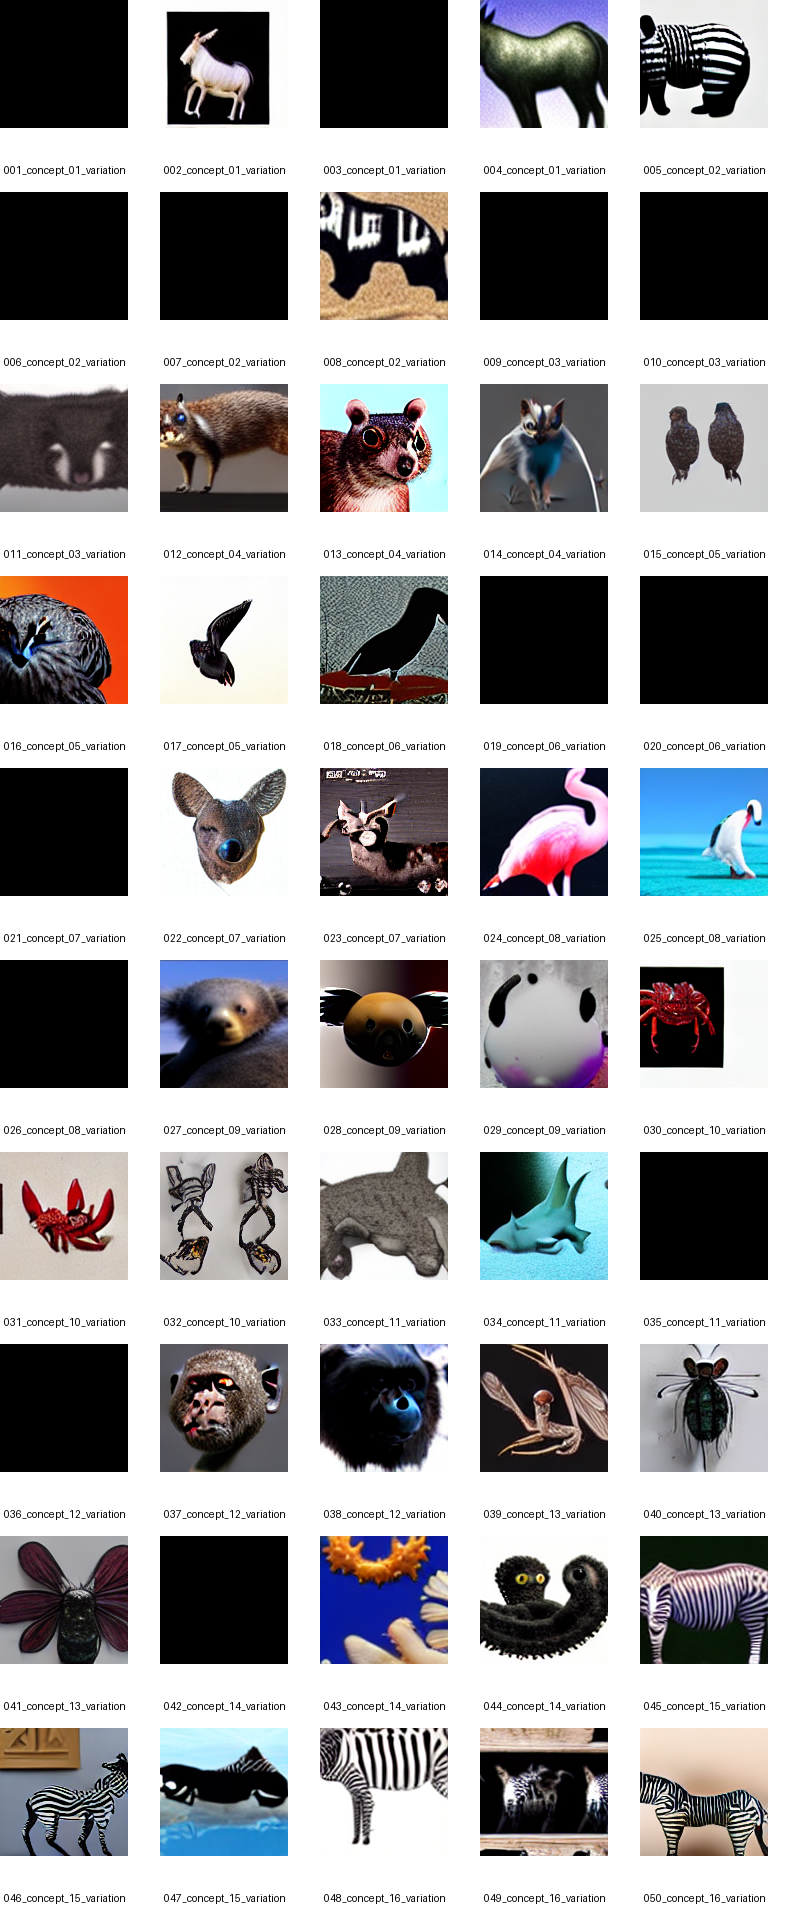

In [56]:

from PIL import Image, ImageDraw
import math

image_files = sorted(
    p for p in OUTPUT_DIR.glob("*.png")
    if p.name != "contact_sheet.png"
)

thumb_size = 160
label_height = 32
columns = 5
rows = math.ceil(len(image_files) / columns)

sheet = Image.new(
    "RGB",
    (columns * thumb_size, rows * (thumb_size + label_height)),
    "white",
)
draw = ImageDraw.Draw(sheet)

for index, path in enumerate(image_files):
    image = Image.open(path).convert("RGB")
    image.thumbnail((thumb_size, thumb_size))

    x = (index % columns) * thumb_size
    y = (index // columns) * (thumb_size + label_height)

    sheet.paste(image, (x, y))
    draw.text(
        (x + 4, y + thumb_size + 4),
        path.stem[:24],
        fill="black",
    )

contact_path = OUTPUT_DIR / "contact_sheet.jpg"
sheet.save(contact_path, quality=90)

print("Contact sheet saved:", contact_path)
display(sheet)


In [57]:

FINAL_OUTPUT_DRIVE.mkdir(parents=True, exist_ok=True)

for path in OUTPUT_DIR.iterdir():
    if path.is_file():
        shutil.copy2(path, FINAL_OUTPUT_DRIVE / path.name)

print("Generated images copied to:", FINAL_OUTPUT_DRIVE)
print("Images:", len(list(FINAL_OUTPUT_DRIVE.glob("*.png"))))
print("Contact sheet:", FINAL_OUTPUT_DRIVE / "contact_sheet.jpg")
print("LoRA directory:", CHECKPOINT_DIR)


Generated images copied to: /content/drive/MyDrive/FictionalAnimals/generated_images3
Images: 50
Contact sheet: /content/drive/MyDrive/FictionalAnimals/generated_images3/contact_sheet.jpg
LoRA directory: /content/drive/MyDrive/FictionalAnimals/fictional_animals_lora
